# 11 — Oanda frontier research

This notebook builds a fully invested mean-variance book from Oanda minute bars stored in S3, then walks it forward. It is research. The walk-forward records simulated plans and never sends them.

The traded portfolio is `phi = phi_a + lambda * omega`, with a 20% annualized target. `omega` is the zero-net, unit-variance direction. It is not the held portfolio. The mix sums to 1. Gross exposure of the mix is capped at 2 and each mix weight at 0.30. A zero mix weight is closed. If 20% is outside the feasible range, the target is lowered or raised to the constrained minimum-variance return and the value actually used is logged.

The account does not hold that mix directly. Each name's share of a 25% margin budget is its mix weight divided by the sum of absolute mix weights. Notional is that margin divided by the instrument's margin rate. The equity curve marks to market those notionals, so it matches the book the practice account orders. Margin rates are the current practice-account rates and are held constant through the history.

A daily session ends at 17:00 America/New_York. The bar at 17:00 belongs to the session that is closing. The close is the last minute mid in that session, and the return is a simple close-to-close return. A missing session is absent. It is not filled with zero.

Once a month the notebook clusters shrunk correlations, cuts the tree at 10, 15, and 20 groups, and keeps the most liquid name in each group. Liquidity is the lowest median spread over the trailing 756 sessions, and a name must have all 756 candles. The size with the higher trailing 12-month Sharpe of daily returns net of half-spread turnover is traded. A tie keeps the smaller list. Each day after that, only the mean, covariance, and weights of the frozen list are refreshed. Ledoit-Wolf is the covariance that is inverted. Sample and one-factor covariances are reported for comparison.

The last section can submit one practice-account plan for the latest completed session. `SUBMIT_TODAY_TO_PRACTICE` defaults to `False`. Leave it off while reading the research output.

In [4]:
import logging
import os
import sys
from datetime import date
from pathlib import Path

os.environ.setdefault("AWS_PROFILE", "trading")
os.environ.setdefault("S3_BUCKET", "trading-data-centheos")
os.environ["DATA_STORE"] = "s3"

_here = Path.cwd().resolve()
for _cand in [_here, *_here.parents]:
    if (_cand / "schemas.py").exists():
        _root = _cand
        break
else:
    raise RuntimeError("Could not locate project root (no schemas.py found)")
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
import pandas as pd
from IPython.display import display

from ohlcv_store import get_ohlcv_store
from oanda_portfolio import FrontierConfig, load_oanda_daily_panel, simulate, submit_plan
from oanda_portfolio.plan import build_plan
from oanda_portfolio.practice import PlanStore, PracticeBroker

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")
pd.set_option("display.max_rows", 40)
pd.set_option("display.width", 120)

## Load the daily panel

`HISTORY_START` limits the minute bars that are read. A 756-session window plus 12 scored months is the burn-in, so a 2022 start does not produce a chosen book until that history exists. A symbol that fails to read is excluded and listed. It does not stop the rest of the universe.

In [5]:
HISTORY_START = "2022-01-01"
from_ts = int(pd.Timestamp(HISTORY_START, tz="UTC").timestamp() * 1000)

store = get_ohlcv_store()
closes, spreads, load_failures = load_oanda_daily_panel(store, from_ts=from_ts)
print(f"sessions={len(closes)} symbols={closes.shape[1]} failed_reads={len(load_failures)}")
print(f"first={closes.index.min().date()} last={closes.index.max().date()}")
pd.DataFrame(load_failures)

WARNING oanda_portfolio.daily: Excluded open session(s) before the 17:00 New York close: 2026-10-26
INFO oanda_portfolio.daily: Built daily panels for 127 symbols, excluded 0


sessions=1273 symbols=127 failed_reads=0
first=2022-01-03 last=2026-10-23


""


## Walk-forward

Plans in this result use a research NAV of 100,000 and status `simulated`. `submit_plan` refuses that status, so these rows cannot be sent by accident.

In [6]:
broker = PracticeBroker()
margin_rates = broker.margin_rates(list(closes.columns))
config = FrontierConfig(margin_rates=margin_rates)
result = simulate(closes, spreads, config)
print(
    f"plans={len(result.plans)} skips={len(result.skips)} "
    f"exclusions={len(result.exclusions)} chosen_days={len(result.chosen_returns)} "
    f"margin_rates={len(margin_rates)}"
)

INFO oandapyV20.oandapyV20: setting up API-client for environment practice
INFO oandapyV20.oandapyV20: performing request https://api-fxpractice.oanda.com/v3/accounts/101-011-29293917-001/summary
INFO oandapyV20.oandapyV20: performing request https://api-fxpractice.oanda.com/v3/accounts/101-011-29293917-001/instruments
INFO oanda_portfolio.practice: Loaded margin rates for 127 instruments
INFO oanda_portfolio.simulate: Walk-forward marks to market margin notionals at 25% of NAV using 127 margin rates
ERROR oanda_portfolio.simulate: Selection of 10 assets failed on 2022-01-03: only 0 assets have 756 returns
ERROR oanda_portfolio.simulate: Selection of 15 assets failed on 2022-01-03: only 0 assets have 756 returns
ERROR oanda_portfolio.simulate: Selection of 20 assets failed on 2022-01-03: only 0 assets have 756 returns
ERROR oanda_portfolio.simulate: Selection of 10 assets failed on 2022-02-01: only 0 assets have 756 returns
ERROR oanda_portfolio.simulate: Selection of 15 assets failed 

plans=454 skips=123 exclusions=423 chosen_days=435 margin_rates=127


In [7]:
sharpe = pd.Series(result.sharpe_by_size, name="annualized_sharpe").sort_index()
sharpe

10   -0.760186
15   -0.525642
20   -0.128180
Name: annualized_sharpe, dtype: float64

In [8]:
pd.DataFrame(result.exclusions).tail(30)

,session_date,portfolio_size,error,symbol,reason,shortfall
393,2025-04-01,10,NaN,CORN_USD,insufficient pairwise overlap,4.0
394,2025-04-01,10,NaN,SOYBN_USD,insufficient pairwise overlap,4.0
395,2025-04-01,10,NaN,WHEAT_USD,insufficient pairwise overlap,4.0
396,2025-04-01,15,NaN,CHINAH_HKD,fewer than min_overlap returns,756.0
397,2025-04-01,15,NaN,HK33_HKD,insufficient pairwise overlap,17.0
398,2025-04-01,15,NaN,SUGAR_USD,insufficient pairwise overlap,7.0
399,2025-04-01,15,NaN,CORN_USD,insufficient pairwise overlap,4.0
400,2025-04-01,15,NaN,SOYBN_USD,insufficient pairwise overlap,4.0
401,2025-04-01,15,NaN,WHEAT_USD,insufficient pairwise overlap,4.0
402,2025-04-01,20,NaN,CHINAH_HKD,fewer than min_overlap returns,756.0


In [9]:
pd.DataFrame(result.skips)

,session_date,portfolio_size,reason,symbols
0,2025-03-09,10,"rollover deferred, missing ['NATGAS_USD']",[NATGAS_USD]
1,2025-03-09,10,missing daily candle: ['NATGAS_USD'],[NATGAS_USD]
2,2025-03-09,15,"rollover deferred, missing ['CN50_USD', 'NATGA...","[CN50_USD, NATGAS_USD, USB02Y_USD]"
3,2025-03-09,15,"missing daily candle: ['CN50_USD', 'NATGAS_USD...","[CN50_USD, NATGAS_USD, USB02Y_USD]"
4,2025-03-09,20,"rollover deferred, missing ['CN50_USD', 'NATGA...","[CN50_USD, NATGAS_USD, USB02Y_USD]"
...,...,...,...,...
118,2026-09-07,20,"missing daily candle: ['CORN_USD', 'SUGAR_USD']","[CORN_USD, SUGAR_USD]"
119,2026-10-01,20,"rollover deferred, missing ['CHINAH_HKD']",[CHINAH_HKD]
120,2026-10-01,20,missing daily candle: ['CHINAH_HKD'],[CHINAH_HKD]
121,2026-10-19,20,"rollover deferred, missing ['CHINAH_HKD']",[CHINAH_HKD]


sessions=435 total_pnl=-32.67% sharpe=-0.90 max_drawdown=-36.60% last=2026-10-23


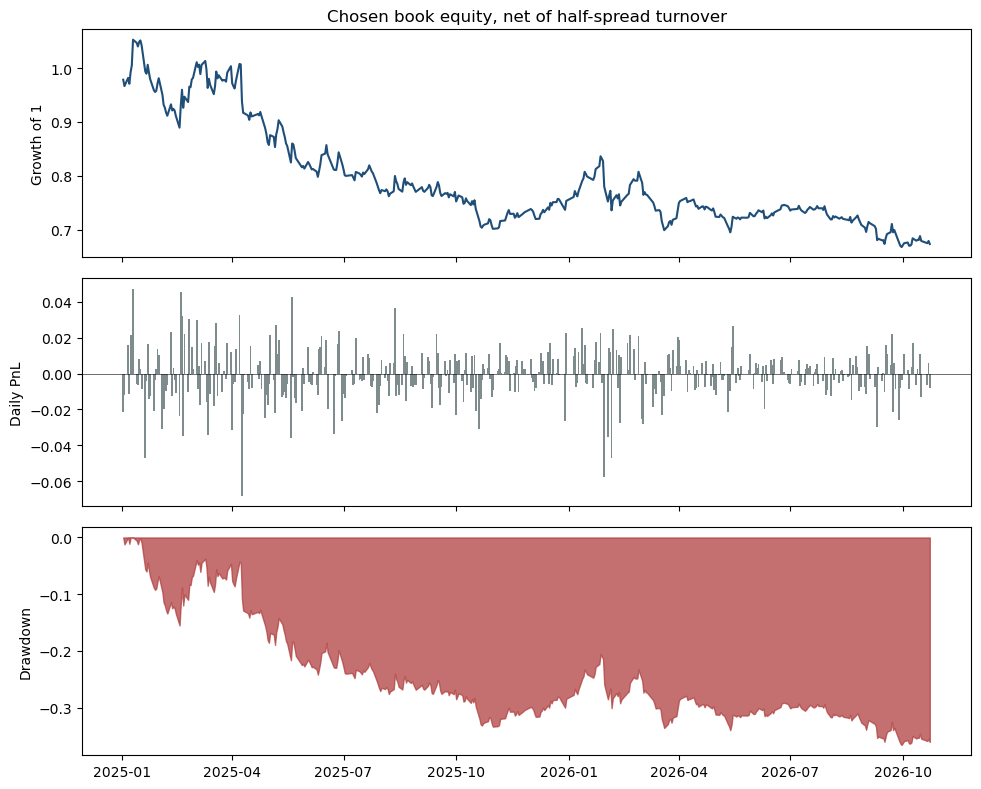

In [10]:
import matplotlib.pyplot as plt

from oanda_portfolio.frontier import annualization_factor

if result.chosen_returns.empty:
    print("No chosen book yet. The burn-in is 756 sessions plus 12 scored months.")
else:
    rets = result.chosen_returns.dropna()
    equity = (1.0 + rets).cumprod()
    drawdown = equity / equity.cummax() - 1.0
    factor = annualization_factor(pd.DatetimeIndex(rets.index))
    sharpe = float(rets.mean() / rets.std(ddof=1) * np.sqrt(factor))
    print(
        f"sessions={len(rets)} total_pnl={float(equity.iloc[-1] - 1.0):.2%} "
        f"sharpe={sharpe:.2f} max_drawdown={float(drawdown.min()):.2%} "
        f"last={rets.index[-1].date()}"
    )
    fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
    axes[0].plot(equity.index, equity.to_numpy(), color="#1f4e79")
    axes[0].set_ylabel("Growth of 1")
    axes[0].set_title("Chosen book equity, net of half-spread turnover")
    axes[1].bar(rets.index, rets.to_numpy(), width=1.5, color="#7f8c8d")
    axes[1].axhline(0, color="black", lw=0.4)
    axes[1].set_ylabel("Daily PnL")
    axes[2].fill_between(drawdown.index, drawdown.to_numpy(), 0, color="#b04040", alpha=0.75)
    axes[2].set_ylabel("Drawdown")
    fig.tight_layout()
    plt.show()
    equity.tail()

mix_names=20 mix_held=13 mix_sum=1.000000 notional_held=13 notional_gross=4.200
margin from notionals=25.00% of NAV
A zero mix weight is closed. Notional is the margin share divided by the margin rate.


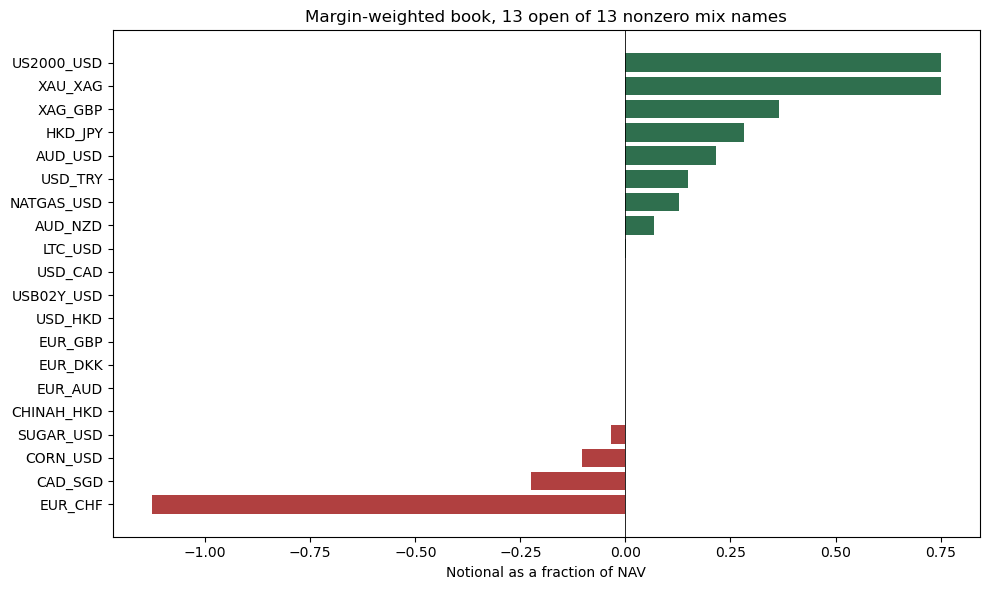

In [11]:
if result.final_weights is None:
    print("No final weights.")
else:
    mix = result.final_mix if result.final_mix is not None else result.final_weights
    notionals = result.final_weights.sort_values()
    held_mask = notionals.abs() > 1e-8
    mix_held = int((mix.abs() > 1e-8).sum())
    print(
        f"mix_names={len(mix)} mix_held={mix_held} mix_sum={mix.sum():.6f} "
        f"notional_held={int(held_mask.sum())} notional_gross={notionals.abs().sum():.3f}"
    )
    if result.config.margin_rates:
        margin = sum(
            abs(float(notionals.get(name, 0.0))) * float(result.config.margin_rates[name])
            for name in notionals.index
            if name in result.config.margin_rates
        )
        print(f"margin from notionals={margin:.2%} of NAV")
    print("A zero mix weight is closed. Notional is the margin share divided by the margin rate.")
    fig, ax = plt.subplots(figsize=(10, 6))
    colors = ["#b04040" if value < 0 else "#2f6f4e" for value in notionals]
    ax.barh(notionals.index, notionals.to_numpy(), color=colors)
    ax.axvline(0, color="black", lw=0.6)
    ax.set_xlabel("Notional as a fraction of NAV")
    ax.set_title(f"Margin-weighted book, {int(held_mask.sum())} open of {mix_held} nonzero mix names")
    fig.tight_layout()
    plt.show()
    notionals

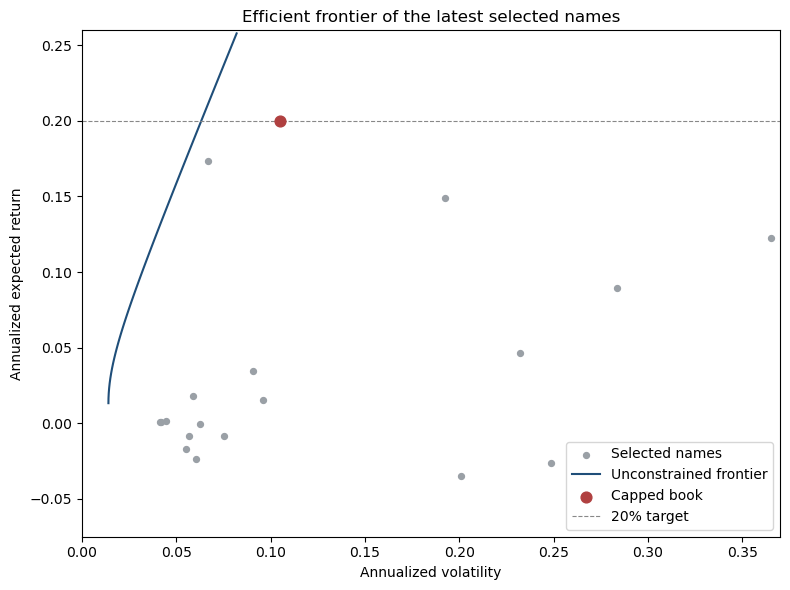

capped book expected return=20.00% vol=10.50%
2 selected names sit past 37% volatility and are left off the x-axis
closed form at 20% would be gross=2.12 max_abs=0.78; the 0.30 and 2.0 caps are what zero names out


In [12]:
import matplotlib.pyplot as plt

from oanda_portfolio.daily import simple_returns
from oanda_portfolio.frontier import annualize_moments

if result.final_weights is None or result.covariance_comparison is None:
    print("No frontier inputs. The final window is shorter than the lookback.")
else:
    names = list(result.final_weights.index)
    window = simple_returns(closes)[names].dropna(how="any").iloc[-config.lookback :]
    mean, covariance, _, _ = annualize_moments(window)
    mu = mean.to_numpy(dtype=float)
    sigma = covariance.to_numpy(dtype=float)
    inv = np.linalg.inv(sigma)
    ones = np.ones(len(mu))
    a = float(ones @ inv @ ones)
    b = float(mu @ inv @ ones)
    c = float(mu @ inv @ mu)
    disc = a * c - b * b
    minimum_return = b / a
    grid = np.linspace(
        minimum_return,
        max(float(mu.max()), config.target_return, minimum_return) + 0.05,
        80,
    )
    variance = (a * grid**2 - 2.0 * b * grid + c) / disc
    curve = grid[variance > 0]
    curve_vol = np.sqrt(variance[variance > 0])
    mix_weights = result.final_mix if result.final_mix is not None else result.final_weights
    held = mix_weights.reindex(mean.index).fillna(0.0).to_numpy(dtype=float)
    held_return = float(held @ mu)
    held_vol = float(np.sqrt(held @ sigma @ held))
    g = (c * (inv @ ones) - b * (inv @ mu)) / disc
    h = (a * (inv @ mu) - b * (inv @ ones)) / disc
    closed = g + h * config.target_return
    asset_vol = np.sqrt(np.diag(sigma))
    x_hi = max(held_vol * 2.2, float(np.quantile(asset_vol, 0.85)) * 1.25, 0.15)
    in_frame = asset_vol <= x_hi
    y_values = np.concatenate([
        mu[in_frame],
        np.array([minimum_return, held_return, config.target_return], dtype=float),
    ])
    y_lo = float(y_values.min()) - 0.04
    y_hi = float(y_values.max()) + 0.06
    shown = (curve_vol <= x_hi) & (curve >= y_lo) & (curve <= y_hi)
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.scatter(asset_vol, mu, s=18, color="#9aa0a6", label="Selected names")
    ax.plot(curve_vol[shown], curve[shown], color="#1f4e79", label="Unconstrained frontier")
    ax.scatter([held_vol], [held_return], s=60, color="#b04040", zorder=3, label="Capped book")
    ax.axhline(config.target_return, color="#888888", ls="--", lw=0.8, label="20% target")
    ax.set_xlim(0, x_hi)
    ax.set_ylim(y_lo, y_hi)
    ax.set_xlabel("Annualized volatility")
    ax.set_ylabel("Annualized expected return")
    ax.set_title("Efficient frontier of the latest selected names")
    ax.legend()
    fig.tight_layout()
    plt.show()
    print(f"capped book expected return={held_return:.2%} vol={held_vol:.2%}")
    beyond = int((asset_vol > x_hi).sum())
    if beyond:
        print(
            f"{beyond} selected names sit past {x_hi:.0%} volatility and are left off the x-axis"
        )
    print(
        f"closed form at {config.target_return:.0%} would be gross={np.abs(closed).sum():.2f} "
        f"max_abs={np.abs(closed).max():.2f}; the 0.30 and 2.0 caps are what zero names out"
    )

In [13]:
if not result.plans:
    print("No simulated plans.")
else:
    latest = result.plans[-1]
    print(
        f"session={latest.session_date} status={latest.status} "
        f"sent_to_broker={latest.sent_to_broker} target_used={latest.target_return_used}"
    )
    display(pd.DataFrame([leg.__dict__ for leg in latest.legs]))
    display(pd.DataFrame(latest.skips))

session=2026-10-23 status=simulated sent_to_broker=False target_used=0.2


,client_order_id,instrument,phase,units,filled_units,status,attempts,position_fill,message
0,20261023r03CADSGD,CAD_SGD,reduce,4526,0,pending,0,REDUCE_ONLY,
1,20261023r05EURCHF,EUR_CHF,reduce,519,0,pending,0,REDUCE_ONLY,
2,20261023r06HKDJPY,HKD_JPY,reduce,-797,0,pending,0,REDUCE_ONLY,
3,20261023r09SUGARUSD,SUGAR_USD,reduce,1234,0,pending,0,REDUCE_ONLY,
4,20261023r11XAUXAG,XAU_XAG,reduce,-5,0,pending,0,REDUCE_ONLY,
5,20261023i01AUDNZD,AUD_NZD,increase,5434,0,pending,0,OPEN_ONLY,
6,20261023i02AUDUSD,AUD_USD,increase,12808,0,pending,0,OPEN_ONLY,
7,20261023i04CORNUSD,CORN_USD,increase,-527,0,pending,0,OPEN_ONLY,
8,20261023i07LTCUSD,LTC_USD,increase,1,0,pending,0,OPEN_ONLY,
9,20261023i08NATGASUSD,NATGAS_USD,increase,393,0,pending,0,OPEN_ONLY,


""


In [14]:
comparison = result.covariance_comparison
if not comparison:
    print("No covariance comparison. The final window is shorter than the lookback.")
else:
    rows = []
    for name in ("ledoit_wolf", "sample", "one_factor"):
        matrix = np.asarray(comparison[name], dtype=float)
        eigenvalues = np.linalg.eigvalsh(matrix)
        rows.append(
            {
                "covariance": name,
                "min_eigenvalue": eigenvalues[0],
                "max_eigenvalue": eigenvalues[-1],
                "condition": eigenvalues[-1] / eigenvalues[0] if eigenvalues[0] > 0 else np.inf,
            }
        )
    print(f"Ledoit-Wolf shrinkage intensity={comparison['shrinkage']:.6f}")
    pd.DataFrame(rows).set_index("covariance")

Ledoit-Wolf shrinkage intensity=0.029825


## Practice account — run by hand

This is the only cell that can place an order. It builds a new plan from the latest completed session, the practice-account NAV, and the current practice positions. It does not resend a simulated research plan.

Set `SUBMIT_TODAY_TO_PRACTICE = True` only for the last session that has reached 17:00 New York. Bars after that close belong to the next session and are ignored until that session closes. The cell refuses a closed session more than four days behind the current New York date. A session the walk-forward skipped, because a held name had no candle, submits the weights carried from the previous plan and records that reason. It still refuses when that session has no carried book. A dropped name is flattened in the reducing phase. If a reducing leg is rejected or partial, nothing further is sent.

The cluster size is the selected list. A name whose optimal weight is zero is not opened, so the account holds fewer names than 10, 15, or 20. The percentage on the OANDA account summary is the margin close-out gauge, `(50% × margin used) / NAV`. This plan targets 25% of NAV as margin used, which that gauge shows as about 12.5%. A gauge reading of 50% is a margin call.

In [15]:
import importlib
import oanda_portfolio.daily as _daily
import oanda_portfolio.plan as _plan
import oanda_portfolio.practice as _practice
_simulate = importlib.import_module("oanda_portfolio.simulate")
importlib.reload(_daily)
importlib.reload(_plan)
importlib.reload(_practice)
importlib.reload(_simulate)
from oanda_portfolio.daily import completed_sessions
from oanda_portfolio.plan import build_plan
from oanda_portfolio.practice import PlanStore, PracticeBroker, submit_plan
from oanda_portfolio.simulate import book_for_session

SUBMIT_TODAY_TO_PRACTICE = True

if not SUBMIT_TODAY_TO_PRACTICE:
    print("Practice submission is off. The cells above are research only.")
else:
    if not result.plans or result.final_weights is None:
        raise RuntimeError("no research plan exists for the latest session")
    closed_sessions = completed_sessions(closes.index)
    if len(closed_sessions) == 0:
        raise RuntimeError("no New York session has reached the 17:00 close")
    latest_session = str(pd.Timestamp(closed_sessions.max()).date())
    book = book_for_session(result, latest_session)
    if book.held:
        print(
            f"session {latest_session} held the {book.list_version} book: {book.reason}"
        )
    today_ny = pd.Timestamp.now(tz="America/New_York").date()
    age_days = (today_ny - date.fromisoformat(latest_session)).days
    if age_days > 4:
        raise RuntimeError(
            f"latest session {latest_session} is {age_days} days behind New York date {today_ny}"
        )
    broker = PracticeBroker()
    current_units = broker.positions()
    names = sorted(set(book.weights) | set(current_units))
    execution = broker.execution_inputs(names)
    note = "practice submission from notebooks/11_oanda_frontier.ipynb"
    if book.held:
        note = f"{note}; held because {book.reason}"
    practice_plan = build_plan(
        session_date=latest_session,
        list_version=book.list_version,
        nav=execution.nav,
        weights=book.weights,
        mids={name: execution.mids[name] for name in book.weights},
        current_units=current_units,
        min_trade_units=config.min_trade_units,
        target_return_used=book.target_return_used,
        trade_steps=execution.trade_steps,
        quote_home_conversions={
            name: execution.quote_home_conversions[name]
            for name in book.weights
        },
        margin_rates={name: execution.margin_rates[name] for name in book.weights},
        margin_capacity=execution.margin_capacity,
        note=note,
    )
    saved = submit_plan(practice_plan, broker, PlanStore(_root / "data" / "oanda_frontier_plans"))
    print(
        f"session={saved.session_date} status={saved.status} nav={saved.nav} "
        f"allocation_scale={saved.allocation_scale:.6f} "
        f"estimated_margin={saved.estimated_margin} "
        f"utilization={saved.margin_utilization:.2%} ceiling={saved.margin_budget}"
    )
    display(pd.DataFrame([leg.__dict__ for leg in saved.legs]))
    account = broker.account_summary()
    used = float(account["marginUsed"])
    nav_now = float(account["NAV"])
    closeout = float(account["marginCloseoutPercent"])
    held_now = broker.positions()
    print(
        f"account positions={len(held_now)} margin_used={used:.2f} "
        f"used/NAV={used / nav_now:.2%} oanda_closeout={closeout:.2%}"
    )

INFO oandapyV20.oandapyV20: setting up API-client for environment practice
INFO oandapyV20.oandapyV20: performing request https://api-fxpractice.oanda.com/v3/accounts/101-011-29293917-001/summary
INFO oandapyV20.oandapyV20: performing request https://api-fxpractice.oanda.com/v3/accounts/101-011-29293917-001/openPositions
INFO oandapyV20.oandapyV20: performing request https://api-fxpractice.oanda.com/v3/accounts/101-011-29293917-001/summary
INFO oandapyV20.oandapyV20: performing request https://api-fxpractice.oanda.com/v3/accounts/101-011-29293917-001/instruments
INFO oandapyV20.oandapyV20: performing request https://api-fxpractice.oanda.com/v3/accounts/101-011-29293917-001/pricing
INFO oanda_portfolio.practice: Execution margin NAV=92760.81 used=26552.90 available=66364.94 used/capacity=28.58% closeout=0.14288 target_used=25% ceiling_used=30% margin_call_percent=0.28577
INFO oanda_portfolio.plan: margin budget 25.04% of NAV split by mix weight and divided by margin rate; utilization 25

session=2026-10-23 status=increasing nav=92760.8085 allocation_scale=1.000000 estimated_margin=23241.092172178556 utilization=25.01% ceiling=27875.35407


,client_order_id,instrument,phase,units,filled_units,status,attempts,position_fill,message
0,20261023r03CADSGD,CAD_SGD,reduce,7967.00,7967.00,filled,1,REDUCE_ONLY,
1,20261023r06EURAUD,EUR_AUD,reduce,-2466.00,-2466.00,filled,1,REDUCE_ONLY,
2,20261023r07EURCHF,EUR_CHF,reduce,455.00,455.00,filled,1,REDUCE_ONLY,
3,20261023r08HKDJPY,HKD_JPY,reduce,-110625.00,-110625.00,filled,1,REDUCE_ONLY,
4,20261023r05CHINAHHKD,CHINAH_HKD,reduce,-0.60,0.00,pending,0,REDUCE_ONLY,
5,20261023r11USDTRY,USD_TRY,reduce,-17949.00,0.00,pending,0,REDUCE_ONLY,
6,20261023i02AUDNZD,AUD_NZD,increase,6231.00,6231.00,filled,1,OPEN_ONLY,
7,20261023i03AUDUSD,AUD_USD,increase,16214.00,16214.00,filled,1,OPEN_ONLY,
8,20261023i06CORNUSD,CORN_USD,increase,-194.00,0.00,skipped,1,OPEN_ONLY,MARKET_HALTED
9,20261023i07LTCUSD,LTC_USD,increase,0.64,0.64,filled,1,OPEN_ONLY,


INFO oandapyV20.oandapyV20: performing request https://api-fxpractice.oanda.com/v3/accounts/101-011-29293917-001/summary
INFO oandapyV20.oandapyV20: performing request https://api-fxpractice.oanda.com/v3/accounts/101-011-29293917-001/openPositions


account positions=14 margin_used=27819.44 used/NAV=30.00% oanda_closeout=14.97%
